In [ ]:
import pandas as pd

In [ ]:
df = pd.read_csv(r'C:\Users\USER\Documents\Kuliah\MIKTI\Programs\Capstone Project\dataset\test9.csv')
df.head()

,month,clean_full_text,tokens,topic,sentiment
0,desember,kiper vietnam puji main muda timnas indonesia ...,"['kiper', 'vietnam', 'puji', 'main', 'muda', '...",Kualifikasi Piala Dunia,Positif
1,desember,piala aff pssi sanjung tampil timnas indonesia...,"['piala', 'aff', 'pssi', 'sanjung', 'tampil', ...",Kualifikasi Piala Dunia,Netral
2,desember,kerepot tahan imbang laos ajar timnas indonesi...,"['kerepot', 'tahan', 'imbang', 'laos', 'ajar',...",Kualifikasi Piala Dunia,Netral
3,desember,susun main timnas indonesia laos struick start...,"['susun', 'main', 'timnas', 'indonesia', 'laos...",Manajemen Tim dan Pelatihan,Positif
4,desember,kalah vietnam pede indonesia semifinal timnas ...,"['kalah', 'vietnam', 'pede', 'indonesia', 'sem...",Kualifikasi Piala Dunia,Netral


## Mapping Sentiment

In [ ]:
sentiment_mapping = {
    'Negatif': 0,
    'Netral': 1,
    'Positif': 2,
}

In [ ]:
df['sentiment'] = df['sentiment'].apply(lambda x: sentiment_mapping[x]) # Mengubah nilai sentimen dari text menjadi numerik

In [ ]:
df.head()

,month,clean_full_text,tokens,topic,sentiment
0,desember,kiper vietnam puji main muda timnas indonesia ...,"['kiper', 'vietnam', 'puji', 'main', 'muda', '...",Kualifikasi Piala Dunia,2
1,desember,piala aff pssi sanjung tampil timnas indonesia...,"['piala', 'aff', 'pssi', 'sanjung', 'tampil', ...",Kualifikasi Piala Dunia,1
2,desember,kerepot tahan imbang laos ajar timnas indonesi...,"['kerepot', 'tahan', 'imbang', 'laos', 'ajar',...",Kualifikasi Piala Dunia,1
3,desember,susun main timnas indonesia laos struick start...,"['susun', 'main', 'timnas', 'indonesia', 'laos...",Manajemen Tim dan Pelatihan,2
4,desember,kalah vietnam pede indonesia semifinal timnas ...,"['kalah', 'vietnam', 'pede', 'indonesia', 'sem...",Kualifikasi Piala Dunia,1


## Splitting Data

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(df['clean_full_text'], df['sentiment'], test_size=0.15, random_state=42) # Split data, 15% testing 85% latih

## Feature Extraction

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [ ]:
vectorizer = TfidfVectorizer(max_features=5000) # Vectorizer dengan fitur maksimal 5000

In [ ]:
# Mengubah data menjadi vektor
X_train_vec = vectorizer.fit_transform(X_train).toarray()
X_test_vec = vectorizer.transform(X_test).toarray()

## Model

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

In [ ]:
model = RandomForestClassifier(random_state=42)

In [ ]:
# Hyperparameter Tuning
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid_search = GridSearchCV(estimator=model, param_grid=param_grid,
                           scoring='f1_macro', cv=3, verbose=2, n_jobs=-1)

In [ ]:
grid_search.fit(X_train_vec, y_train)

Fitting 3 folds for each of 108 candidates, totalling 324 fits


GridSearchCV(cv=3, estimator=RandomForestClassifier(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [None, 10, 20, 30],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [100, 200, 300]},
             scoring='f1_macro', verbose=2)

In [ ]:
# Mengambil hyperparameter terbaik
best_params = grid_search.best_params_
best_model = grid_search.best_estimator_

print(best_params)

{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 300}


## Evaluate Model

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [ ]:
y_pred = best_model.predict(X_test_vec) # Membuat prediksi dengan model

In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.8337468982630273


In [ ]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["negative", "neutral", "positive"]))


Classification Report:
              precision    recall  f1-score   support

    negative       0.94      0.58      0.71       128
     neutral       0.79      0.99      0.88       420
    positive       0.91      0.71      0.80       258

    accuracy                           0.83       806
   macro avg       0.88      0.76      0.80       806
weighted avg       0.85      0.83      0.83       806



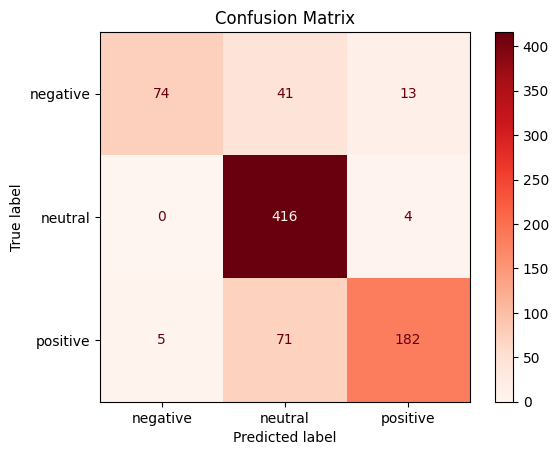

In [ ]:
class_names = ["negative", "neutral", "positive"]

disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_test, y_pred), display_labels=class_names)
disp.plot(cmap='Reds', values_format='d')
plt.title('Confusion Matrix')
plt.show()